# Analysis for PsyNamic Manuscript

## Analysis of data fetching pipeline
### PubMed Fetch Results


How many articles were retrieved from PubMed via API up to the cutoff (with new search string)

In [1]:
import os
import sys
sys.path.append(os.path.abspath(".."))
import pandas as pd


# ---- Parameters ----
# Cutoff of the analysed dataset (PubMed [Date - Create]); the PubMed fetch ends at this date.
CUTOFF = pd.Timestamp("2026-10-31")
PUBMED_FETCH_FILE = "../data/analysis/pubmed_results_19000101_20261031_00-03-23.csv"
# Output of the new relevance model on PUBMED_FETCH_FILE (column `prediction`)
RELEVANCE_FILE = "../data/analysis/studies_20261031_00-03-00.csv"
# Seed file for the automated route, written by the deduplication below
DEDUP_OUT_FILE = "../data/analysis/studies_relevant_deduplicated_excluded_20261031_00-00-00.csv"

df = pd.read_csv(PUBMED_FETCH_FILE, dtype={"pubmed_id": str})
print(f'Total articles without abstract: {df["abstract"].isna().sum()}')
print(f'Total articles retrieved: {len(df)}')
# check if there are any duplicates in the new pubmed fetch results based on pubmed_id
duplicates_pubmed_id = df[df.duplicated(subset=['pubmed_id'], keep=False)]
print(f'Number of duplicate articles in new pubmed fetch results based on pubmed_id: {len(duplicates_pubmed_id)}')

df_2025_pubmed_fetch_new_string = df[df["entrez_year"] < 2026]
print(f'Total articles retrieved until 2025: {len(df_2025_pubmed_fetch_new_string)}')
print(f'Total articles without abstract until 2025: {len(df_2025_pubmed_fetch_new_string[df_2025_pubmed_fetch_new_string["abstract"].isna()])}')


Total articles without abstract: 4983
Total articles retrieved: 22292
Number of duplicate articles in new pubmed fetch results based on pubmed_id: 0
Total articles retrieved until 2025: 20812
Total articles without abstract until 2025: 4873


How many articles were retrieved from PubMed via API in 2026 (with old search string)

In [2]:
df = pd.read_csv("../data/history/pubmed_results_20240105_20260320_00-00-10.csv", dtype={"pubmed_id": str})

print(f'Total articles retrieved: {len(df)}')
# check if there are any duplicates in the new pubmed fetch results based on pubmed_id
duplicates_pubmed_id = df[df.duplicated(subset=['pubmed_id'], keep=False)]
print(f'Number of duplicate articles in new pubmed fetch results based on pubmed_id: {len(duplicates_pubmed_id)}')

df_2025_pubmed_fetch = df[df["entrez_year"] < 2026]
print(f'Total articles retrieved until 2025: {len(df_2025_pubmed_fetch)}')
print(f'Total articles without abstract until 2025: {len(df_2025_pubmed_fetch[df_2025_pubmed_fetch["abstract"].isna()])}')


Total articles retrieved: 1323
Number of duplicate articles in new pubmed fetch results based on pubmed_id: 0
Total articles retrieved until 2025: 1172
Total articles without abstract until 2025: 15


In [3]:
df_2026_pubmed_fetch = df[df["entrez_year"] == 2026]
print(f'Total articles retrieved in 2026: {len(df_2026_pubmed_fetch)}')
print(f'Total articles without abstract in 2026: {len(df_2026_pubmed_fetch[df_2026_pubmed_fetch["abstract"].isna()])}')

Total articles retrieved in 2026: 151
Total articles without abstract in 2026: 1


In [4]:
# from data.get_pubmed_data import get_pubmed_id_from_title
# from tqdm import tqdm


# as_file = "../data/analysis/as_review_studies_relevant_with_info_20240101_00-00-00.csv"
# df_as_relevant = pd.read_csv(as_file)
# # count how many articles don't have a pubmed_id
# num_missing_pubmed_id = df_as_relevant['pubmed_id'].isna().sum()
# print(f'Number of articles in ASreview dataset without pubmed_id: {num_missing_pubmed_id}')


# # improve pubmedid matching
# for idx, row in tqdm(df_as_relevant.iterrows(), total=len(df_as_relevant)):
#     pubmed_id = row['pubmed_id']
#     if pd.isna(pubmed_id):
#         pubmed_id = get_pubmed_id_from_title(row['title'])
#         if pubmed_id:
#             df_as_relevant.at[idx, 'pubmed_id'] = pubmed_id
#             df_as_relevant.at[idx, 'pubmed_url'] = f'https://pubmed.ncbi.nlm.nih.gov/{pubmed_id}/'

# # check again how many articles don't have a pubmed_id
# num_missing_pubmed_id = df_as_relevant['pubmed_id'].isna().sum()
# print(f'Number of articles in ASreview dataset without pubmed_id after matching: {num_missing_pubmed_id}')

# # write back to csv
# df_as_relevant.to_csv("../data/analysis/as_review_studies_relevant_with_info_20240101_00-00-00.csv", index=False)




In [5]:
as_file = "../data/analysis/as_review_studies_relevant_with_info_20240101_00-00-00.csv"
df_as_relevant = pd.read_csv(as_file)
# convert pubmed_id to from float to int and then to string, while keeping NaN values as is
df_as_relevant['pubmed_id'] = df_as_relevant['pubmed_id'].apply(lambda x: str(int(x)) if pd.notna(x) else x)    

duplicates_as_relevant_pubmed_id = df_as_relevant[df_as_relevant.duplicated(subset=['pubmed_id'], keep=False)]
print(f'Number of duplicate articles in ASreview dataset based on pubmed_id: {len(duplicates_as_relevant_pubmed_id)}')

# print sorted duplicates (title + pubmedId) based on pubmed_id, where pubmed_id is not null
print(duplicates_as_relevant_pubmed_id.sort_values(by="pubmed_id")[["title", "pubmed_id"]].dropna())


Number of duplicate articles in ASreview dataset based on pubmed_id: 925
                                                  title pubmed_id
162   Psilocybin can occasion mystical-type experien...  16826400
165   Psilocybin can occasion mystical-type experien...  16826400
2117  Effects of nicotine on the neurophysiological ...  24478731
2119  Effects of nicotine on the neurophysiological ...  24478731
34    LSD Acutely Impairs Fear Recognition and Enhan...  27249781
52    LSD acutely impairs fear recognition and enhan...  27249781
808   Ketamine for treatment of mood disorders and s...  35166663
812   Ketamine for treatment of mood disorders and s...  35166663


Are there any duplicates in the 2025 PubMed API data? Or in the ASreview retrieved dataset?

In [6]:
mask = df_as_relevant['pubmed_id'].notna()

duplicates = df_as_relevant[
    mask &
    df_as_relevant.duplicated(subset=['pubmed_id'], keep=False)
]

print(f"Number of duplicate articles in ASreview dataset (excluding NaN): {len(duplicates)}")
duplicates_no_nan = df_2025_pubmed_fetch[df_2025_pubmed_fetch.duplicated(subset=['pubmed_id'], keep=False) & df_2025_pubmed_fetch['pubmed_id'].notnull()]
print(f'Number of duplicate articles in 2025 PubMed API dataset: {len(duplicates_no_nan)}')

duplicates_new_string = df_2025_pubmed_fetch_new_string[df_2025_pubmed_fetch_new_string.duplicated(subset=['pubmed_id'], keep=False)]
print(f'Number of duplicate articles in 2025 PubMed API dataset with new string: {len(duplicates_new_string)}')


Number of duplicate articles in ASreview dataset (excluding NaN): 8
Number of duplicate articles in 2025 PubMed API dataset: 0
Number of duplicate articles in 2025 PubMed API dataset with new string: 0


### Relevant Studies from PubMed API
How many articles were classified relevant from PubMed API data until 31.12.2025 (old string)?

In [7]:
df_rel = pd.read_csv("../data/history/studies_20260320_00-09-37.csv")
df_rel_2025 = df_rel[df_rel["entrez_year"] <= 2025]
print(f'Total articles until 2025: {len(df_rel_2025)}')
df_rel_2025_incl = df_rel_2025[df_rel_2025["prediction"] == 1]
print(f'Total articles classified relevant until 2025: {len(df_rel_2025_incl)}')
print(f'Total articles classified irrelevant until 2025: {len(df_rel_2025[df_rel_2025["prediction"] == 0])}')


Total articles until 2025: 1157
Total articles classified relevant until 2025: 634
Total articles classified irrelevant until 2025: 523


How many articles were classified relevant by the new relevance model (PubMed fetch up to the cutoff)?

In [8]:
df_rel_new_string = pd.read_csv(RELEVANCE_FILE, dtype={"pubmed_id": str})
# Records without abstract are classified on the title only, but populate.py does not load them: drop them here
no_abstract = df_rel_new_string["abstract"].isna()
print(f'Total articles: {len(df_rel_new_string)}, without abstract (not loaded): {no_abstract.sum()} '
      f'(of which classified relevant: {(no_abstract & (df_rel_new_string["prediction"] == 1)).sum()})')
df_rel_new = df_rel_new_string[~no_abstract & (df_rel_new_string["entrez_year"] <= CUTOFF.year)].copy()
df_rel_new_incl = df_rel_new[df_rel_new["prediction"] == 1].copy()
df_rel_new_excl = df_rel_new[df_rel_new["prediction"] == 0].copy()
print(f'Total articles with abstract: {len(df_rel_new)}')
print(f'Total articles classified relevant up to the cutoff: {len(df_rel_new_incl)}')
print(f'Total articles classified irrelevant up to the cutoff: {len(df_rel_new_excl)}')


Total articles: 22292, without abstract (not loaded): 4983 (of which classified relevant: 259)
Total articles with abstract: 17309
Total articles classified relevant up to the cutoff: 6078
Total articles classified irrelevant up to the cutoff: 11231


Are there any samples determined as relevant from new Pubmed search which were manually determined as irrelevant (not irrelevant after stopping criteria)? (action required, remove them from merged database)

In [9]:
# from tqdm import tqdm

# def read_in_asreview() -> list[pd.DataFrame]:
#     input_file = "/home/veral/PsyNamic/data/raw_data/asreview_dataset_all_Psychedelic Study.csv"
#     df = pd.read_csv(input_file)
#     df['title'] = df['title'].str.lower()
#     included = df[df['included'] == 1]
#     excluded = df[df['included'] == 0]
#     excluded_after_stopping = df[df['included'].isna()]

#     return [included, excluded, excluded_after_stopping, df]

# _, excluded, excluded_after_stopping, _ = read_in_asreview()
# excluded['pubmed_id'] = None
# for idx, row in tqdm(excluded.iterrows(), total=len(excluded)):
#     title = row['title']
#     pubmed_id = get_pubmed_id_from_title(title)
#     excluded.at[idx, 'pubmed_id'] = pubmed_id

# excluded.to_csv("../data/analysis/excluded_with_pubmed_id.csv", index=False)

# for idx, row in tqdm(excluded_after_stopping.iterrows(), total=len(excluded_after_stopping)):
#     title = row['title']
#     pubmed_id = get_pubmed_id_from_title(title)
#     excluded_after_stopping.at[idx, 'pubmed_id'] = pubmed_id

# excluded_after_stopping.to_csv("../data/analysis/excluded_after_stopping_with_pubmed_id.csv", index=False)  



Number of overlaps between ASReview included and irrelevant studies until 2025 (pubmed_id): 74
Number of overlaps between ASReview included and relevant studies until 2025 (pubmed_id): 2178


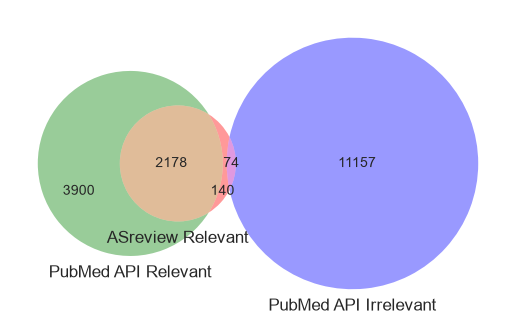

In [10]:
from analysis import compare_dfs
from matplotlib_venn import venn3


excluded = pd.read_csv("../data/analysis/as_review_studies_excluded_with_pubmed_id.csv", dtype={"pubmed_id": str})
excluded_after_stopping = pd.read_csv("../data/analysis/as_review_studies_excluded_after_stopping_with_pubmed_id.csv", dtype={"pubmed_id": str})



nr, matches = compare_dfs(df_as_relevant, df_rel_new_excl, ['pubmed_id'], ['pubmed_id'])
print(f'Number of overlaps between ASReview included and irrelevant studies until 2025 (pubmed_id): {nr}')
nr, matches = compare_dfs(df_as_relevant, df_rel_new_incl, ['pubmed_id'], ['pubmed_id'])
print(f'Number of overlaps between ASReview included and relevant studies until 2025 (pubmed_id): {nr}')

sets = [
    set(df_as_relevant['pubmed_id'].dropna()),
    set(df_rel_new_incl['pubmed_id'].dropna()),
    set(df_rel_new_excl['pubmed_id'].dropna()),

]
v = venn3(sets,    
      ['ASreview Relevant', 'PubMed API Relevant', 'PubMed API Irrelevant'])

# move 3. and 4. label down
v.get_label_by_id('100').set_y(-0.1)
v.get_label_by_id('010').set_y(-0.1)

Number of overlaps between ASReview excluded and relevant studies until 2025 (pubmed_id): 93
Number of overlaps between ASReview excluded after stopping and relevant studies until 2025 (pubmed_id): 102


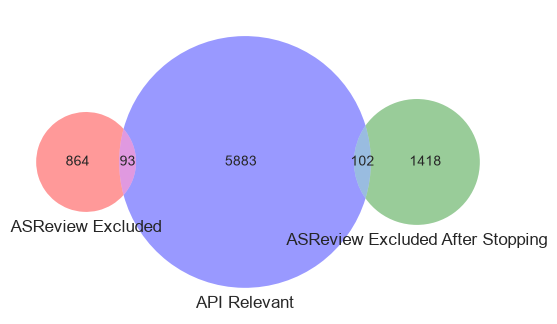

In [11]:
nr, matches_excluded = compare_dfs(excluded, df_rel_new_incl, ['pubmed_id'], ['pubmed_id'])
print(f'Number of overlaps between ASReview excluded and relevant studies until 2025 (pubmed_id): {nr}')

nr, matches_excluded_after_stopping = compare_dfs(excluded_after_stopping, df_rel_new_incl, ['pubmed_id'], ['pubmed_id'])
print(f'Number of overlaps between ASReview excluded after stopping and relevant studies until 2025 (pubmed_id): {nr}')

sets = [
    set(excluded['pubmed_id'].dropna()),
    set(excluded_after_stopping['pubmed_id'].dropna()),
    set(df_rel_new_incl['pubmed_id'].dropna())
]
venn3(sets, ['ASReview Excluded', 'ASReview Excluded After Stopping', 'API Relevant'])


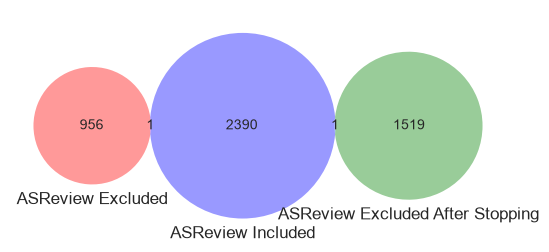

In [12]:
sets = [
    set(excluded['pubmed_id'].dropna()),
    set(excluded_after_stopping['pubmed_id'].dropna()),
    set(df_as_relevant['pubmed_id'].dropna())
]

venn3(sets, ['ASReview Excluded', 'ASReview Excluded After Stopping', 'ASReview Included'])

How many articles from classified as relevant from PubMed API data until 31.12.2025 (new string) which are in the ASReview included dataset?

In [13]:
nr, matches = compare_dfs(df_as_relevant, df_rel_new_incl, ['pubmed_id'], ['pubmed_id'])
print(f'Number of overlaps between ASReview included and relevant studies until 2025 (pubmed_id): {nr}')
print(matches["pubmed_id_df1"].nunique())
vc = matches["pubmed_id_df1"].value_counts()


duplicated_ids = vc[vc > 1]
print(duplicated_ids)

Number of overlaps between ASReview included and relevant studies until 2025 (pubmed_id): 2178
2178
pubmed_id_df1
16826400    2
35166663    2
27249781    2
Name: count, dtype: int64


How many articles of the api results with the new search string were already included in the dataset of the old search string?

In [14]:
nr, matches = compare_dfs(df_rel_2025_incl, df_rel_new_incl, ['pubmed_id'], ['pubmed_id'])
print(f'Number of overlaps between relevant studies until 2025 with old and new string (pubmed_id): {nr}')

Number of overlaps between relevant studies until 2025 with old and new string (pubmed_id): 620


Are there any sample determined as not relevant from new Pubmed search which were manually determined as relevant? (no action required because they are in AS database)

In [15]:
nr, matches = compare_dfs(df_rel_new_excl, df_as_relevant, ['pubmed_id'], ['pubmed_id'])
print(f'Number of overlaps between ASReview excluded and relevant studies until 2025 (pubmed_id): {nr}')

Number of overlaps between ASReview excluded and relevant studies until 2025 (pubmed_id): 74


### Total relevant studies up to the cutoff
Merge of the manual route (ASReview included) and the automated route (PubMed, classified relevant by the new relevance model).
Automated records are removed if they match, on **normalised PMID or DOI**:
1. a record excluded in ASReview (`included=0`) or never screened because of the stopping rule;
2. a record included in ASReview (already in the manual set);
3. an earlier automated record (duplicate within the fetch).

Within the manual set, duplicates are matched on PMID only (shared DOIs there are journal-supplement DOIs of different conference abstracts).

Title matches are **not** removed; they are listed in `duplicates_title.csv` for a manual check.

In [16]:
import re


def norm_pmid(s: pd.Series) -> pd.Series:
    """'37258715.0' / ' 37258715 ' -> '37258715'; empty -> NA"""
    s = s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    return s.mask(s == "")


def norm_doi(s: pd.Series) -> pd.Series:
    """lower case, without https://doi.org/ or doi: prefix; empty -> NA"""
    s = (s.astype("string").str.strip().str.lower()
         .str.replace(r"^(https?://(dx\.)?doi\.org/|doi:\s*)", "", regex=True))
    return s.mask(s == "")


def norm_title(s: pd.Series) -> pd.Series:
    return s.astype("string").str.lower().str.replace(r"[^a-z0-9]", "", regex=True)


for d in (df_as_relevant, excluded, excluded_after_stopping, df_rel_new_incl):
    d["pmid_norm"] = norm_pmid(d["pubmed_id"])
    d["doi_norm"] = norm_doi(d["doi"])


def match(d: pd.DataFrame, ref: pd.DataFrame) -> tuple[pd.Series, pd.Series]:
    """Boolean masks: rows of d matching ref by PMID, and by DOI only (not PMID)."""
    by_pmid = d["pmid_norm"].isin(set(ref["pmid_norm"].dropna()))
    by_doi = d["doi_norm"].isin(set(ref["doi_norm"].dropna()))
    return by_pmid, by_doi & ~by_pmid


print("=== INPUT DATASETS ===")
print(f"ASReview relevant articles:              {len(df_as_relevant):,}")
print(f"PubMed API relevant articles (cutoff):   {len(df_rel_new_incl):,}")
print(f"ASReview excluded / after stopping:      {len(excluded):,} / {len(excluded_after_stopping):,}")


=== INPUT DATASETS ===
ASReview relevant articles:              3,313
PubMed API relevant articles (cutoff):   6,078
ASReview excluded / after stopping:      2,370 / 3,939


In [17]:
auto = df_rel_new_incl.copy()
all_excluded = pd.concat([excluded, excluded_after_stopping], ignore_index=True)

# STEP 1: remove records excluded in ASReview (incl. not reached before the stopping rule)
by_pmid, by_doi = match(auto, all_excluded)
auto_1 = auto[~(by_pmid | by_doi)]
print("STEP 1: Remove ASReview excluded / excluded after stopping")
print(f"  removed by PMID: {by_pmid.sum():,}, by DOI only: {by_doi.sum():,}")
print(f"  remaining:       {len(auto_1):,}")

# STEP 2: remove records already in the manual (ASReview included) set
by_pmid, by_doi = match(auto_1, df_as_relevant)
auto_2 = auto_1[~(by_pmid | by_doi)]
print("\nSTEP 2: Remove ASReview included overlap")
print(f"  removed by PMID: {by_pmid.sum():,}, by DOI only: {by_doi.sum():,}")
print(f"  remaining:       {len(auto_2):,}")

# STEP 3: duplicates within the automated set
dup = ((auto_2["pmid_norm"].notna() & auto_2["pmid_norm"].duplicated())
       | (auto_2["doi_norm"].notna() & auto_2["doi_norm"].duplicated()))
auto_final = auto_2[~dup].copy()
print("\nSTEP 3: Remove duplicates within the automated set")
print(f"  removed:         {dup.sum():,}")
print(f"  remaining:       {len(auto_final):,}")

# Duplicates within the manual set (kept in the database, removed from the analysed set as before).
# PMID only: within ASReview, shared DOIs are conference abstracts of one journal supplement
# (checked 8 Nov 2026: 18 DOI groups, all with different titles), not duplicates.
as_dup = df_as_relevant["pmid_norm"].notna() & df_as_relevant["pmid_norm"].duplicated()
print(f"\nDuplicates within ASReview relevant (PMID): {as_dup.sum():,}")
print(df_as_relevant.loc[as_dup, ["id", "title", "pubmed_id", "doi"]])

merged_v2 = pd.concat([df_as_relevant[~as_dup], auto_final], ignore_index=True)
print("\n=== FINAL RESULT ===")
print(f"Manual (ASReview included, deduplicated): {(~as_dup).sum():,}")
print(f"Automated (PubMed, deduplicated):         {len(auto_final):,}")
print(f"Merged:                                   {len(merged_v2):,}")


STEP 1: Remove ASReview excluded / excluded after stopping
  removed by PMID: 195, by DOI only: 127
  remaining:       5,756

STEP 2: Remove ASReview included overlap
  removed by PMID: 2,177, by DOI only: 115
  remaining:       3,464

STEP 3: Remove duplicates within the automated set
  removed:         0
  remaining:       3,464

Duplicates within ASReview relevant (PMID): 4
        id                                              title pubmed_id  \
52    2104  LSD acutely impairs fear recognition and enhan...  27249781   
165   3180  Psilocybin can occasion mystical-type experien...  16826400   
812   4543  Ketamine for treatment of mood disorders and s...  35166663   
2119  5398  Effects of nicotine on the neurophysiological ...  24478731   

                           doi  
52                         NaN  
165                        NaN  
812                        NaN  
2119  10.3389/fpsyt.2014.00003  

=== FINAL RESULT ===
Manual (ASReview included, deduplicated): 3,309
Automated

Remaining title matches (not removed, for manual checking)

In [18]:
merged_v2["title_norm"] = norm_title(merged_v2["title"])
title_dup = merged_v2[merged_v2["title_norm"].notna() & (merged_v2["title_norm"] != "")
                      & merged_v2.duplicated(subset=["title_norm"], keep=False)]
title_dup = title_dup.sort_values("title_norm")
print(f"Records in merged dataset sharing a normalised title: {len(title_dup)} "
      f"({title_dup['title_norm'].nunique()} titles)")
n_cross = title_dup.groupby("title_norm")["id"].apply(
    lambda ids: (ids.isin(df_as_relevant["id"]).any() and (~ids.isin(df_as_relevant["id"])).any())).sum()
print(f"  of which titles shared between a manual and an automated record: {n_cross}")
title_dup[["id", "title", "year", "entrez_year", "pubmed_id", "doi"]].to_csv("../analysis/duplicates_title.csv", index=False)


Records in merged dataset sharing a normalised title: 87 (43 titles)


  of which titles shared between a manual and an automated record: 25


Write the deduplicated automated set (seed file for the database)

In [19]:
# populate.py uses the `id` column as primary key: automated ids (= PMIDs) must not collide with ASReview ids
collisions = set(auto_final["id"].astype(int)) & set(df_as_relevant["id"].astype(int))
print(f"ID collisions between automated and manual records: {len(collisions)} {sorted(collisions)[:20]}")
assert not collisions, "id collision: populate.py would fail"

auto_final.drop(columns=["pmid_norm", "doi_norm"]).to_csv(DEDUP_OUT_FILE, index=False)
print(f"Wrote {len(auto_final):,} studies to {DEDUP_OUT_FILE}")


ID collisions between automated and manual records: 0 []


Wrote 3,464 studies to ../data/analysis/studies_relevant_deduplicated_excluded_20261031_00-00-00.csv


## Analysis of predictions
### Classification predictions

In [20]:
merged_df = merged_v2.copy()
merged_df.head()

,id,text,type_of_reference,name_of_database,number,keywords,language,notes,year,start_page,...,asreview_ranking,pubmed_url,pubmed_id,pmid_norm,doi_norm,prediction,probability,pub_date,entrez_year,title_norm
0,6152,Ketamine Versus Midazolam for Recurrence of Su...,JOUR,NaN,NaN,"['Depression', 'Ketamine', 'Midazolam', 'Recur...",NaN,[],2020.0,NaN,...,1.0,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,ketamineversusmidazolamforrecurrenceofsuicidal...
1,8321,Acute effects of MDMA and LSD co-administratio...,JOUR,NaN,13,"['Male', 'Humans', 'Female', '*N-Methyl-3,4-me...",eng,"['1740-634x', 'Straumann, Isabelle', 'Ley, Lau...",2023.0,1840-1848,...,2.0,https://pubmed.ncbi.nlm.nih.gov/37258715/,37258715,37258715,10.1038/s41386-023-01609-0,NaN,NaN,NaN,NaN,acuteeffectsofmdmaandlsdcoadministrationinadou...
2,1264,Trial of Psilocybin versus Escitalopram for De...,JOUR,NaN,15,"['Adult', 'Antidepressive Agents/adverse effec...",eng,"['1533-4406', 'Carhart-Harris, Robin', 'Giriba...",2021.0,1402-1411,...,3.0,https://pubmed.ncbi.nlm.nih.gov/33852780/,33852780,33852780,10.1056/nejmoa2032994,NaN,NaN,NaN,NaN,trialofpsilocybinversusescitalopramfordepression
3,7738,Acute autonomic and psychotropic effects of LS...,JOUR,NaN,4,"['*European', '*controlled study', '*human', '...",NaN,[],2015.0,359,...,4.0,NaN,NaN,<NA>,10.3109/15563650.2015.1024953,NaN,NaN,NaN,NaN,acuteautonomicandpsychotropiceffectsoflsdinhea...
4,3640,"Distinct acute effects of LSD, MDMA, and D-amp...",JOUR,NaN,3,"['Adult', 'Affect/drug effects/physiology', 'C...",eng,"['1740-634x', 'Holze, Friederike', 'Orcid: 000...",2020.0,462-471,...,5.0,https://pubmed.ncbi.nlm.nih.gov/31733631/,31733631,31733631,10.1038/s41386-019-0569-3,NaN,NaN,NaN,NaN,distinctacuteeffectsoflsdmdmaanddamphetaminein...


In [21]:
class_data = pd.read_csv("../analysis/export/classification_data.csv")
ner_data = pd.read_csv("../analysis/export/ner_data.csv")
dosage_ner_data = pd.read_csv("../analysis/export/dosage_data.csv")
study_data = pd.read_csv("../analysis/export/study_data.csv")

# check if all ids of merged_df are in study_data
ids_merged = set(merged_df['id'].tolist())
ids_study_data = set(study_data['study_id'].tolist())
ids_not_in_study_data = ids_merged - ids_study_data
print(f'Number of ids in merged dataset that are not in study_data: {len(ids_not_in_study_data)}')
print(f'Number of ids in study_data that are not in merged dataset: {len(ids_study_data - ids_merged)}')

# Only keep rows in study_data where study_id is in merged_df
study_data_2025 = study_data[study_data['study_id'].isin(ids_merged)].reset_index(drop=True)
print(len(study_data_2025))

class_data_2025 = class_data[class_data['study_id'].isin(ids_merged)].reset_index(drop=True)
ner_data_2025 = ner_data[ner_data['study_id'].isin(ids_merged)].reset_index(drop=True)
dosage_ner_data_2025 = dosage_ner_data[dosage_ner_data['Study_ID'].isin(ids_merged)].reset_index(drop=True)

# Analysed set (manual + deduplicated automated, up to the cutoff), also read by analysis_substance_new.ipynb
class_data_2025.to_csv("../analysis/export/classification_data_analysed.csv", index=False)


Number of ids in merged dataset that are not in study_data: 0
Number of ids in study_data that are not in merged dataset: 0
6773


In [22]:
class_data_2025.head()

,study_id,task,label,probability,model,is_multilabel
0,305,Condition,Psychiatric condition,1.0,manual_annotation,True
1,305,Condition,Depression,1.0,manual_annotation,True
2,777,Condition,Psychiatric condition,1.0,manual_annotation,True
3,777,Condition,Depression,1.0,manual_annotation,True
4,1240,Condition,Psychiatric condition,1.0,manual_annotation,True


#### Clean some data anomalies
- Study Type: 3 articles with several study type in manually annotated dataset (artefact from Study Type being modelled as multilabel initially)
- Data Type

In [23]:
study_type_df = class_data_2025[
    class_data_2025["task"] == "Study Type"
]

study_label_counts = (
    study_type_df.groupby("study_id")["label"]
    .nunique()
)

multi_label_study_ids = study_label_counts[study_label_counts > 1].index
# print these rows
print(study_type_df[study_type_df["study_id"].isin(multi_label_study_ids)].sort_values(by="study_id")[["study_id", "label"]])

# Remove "Other" and "Study Protocol" only when another Study Type exists
mask_remove = (
    class_data_2025["study_id"].isin(multi_label_study_ids)
    & class_data_2025["task"].eq("Study Type")
    & class_data_2025["label"].str.strip().str.lower().isin(
        ["other", "study protocol"]
    )
)

df = class_data_2025[~mask_remove].copy()

      study_id                              label
8827       692  Randomized-controlled trial (RCT)
8828       692                              Other


In [24]:
study_type_df = df[
    df["task"] == "Data Type"
]

study_label_counts = (
    study_type_df.groupby("study_id")["label"]
    .nunique()
)

multi_label_study_ids = study_label_counts[study_label_counts > 1].index
print(len(multi_label_study_ids))
# print these rows
print(df[
    df["study_id"].isin(multi_label_study_ids)
    & df["task"].eq("Data Type")
])

# remove "Unknown" or "Not Applicable" when another Data Type exists
mask_remove = (
    df["study_id"].isin(multi_label_study_ids)
    & df["task"].eq("Data Type")
    & df["label"].str.strip().str.lower().isin(
        ["unknown", "not applicable"]
    )
    )

df = df[~mask_remove].copy()

0
Empty DataFrame
Columns: [study_id, task, label, probability, model, is_multilabel]
Index: []


In [25]:
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
import seaborn as sns
import numpy as np
import pandas as pd
from style.colors import GREY, BROWN, BLUE

SKIP_TASKS = ['Clinical Trial Phase', 'Study Conclusion']

TASK_ORDER_GROUP = [
    ['Study Type', 'Data Type', 'Data Collection', 'Number of Participants', 'Sex of Participants', 'Age of Participants', 'Study Purpose', 'Study Control'],
    ['Substances', 'Application Form', 'Regimen', 'Setting', 'Substance Naivety'],
    ['Condition', 'Outcomes']
]

GROUPS = ['Study characteristics', 'Substances','Clinical Measures']


def build_pallette(task, labels_list):
    
    palette = {}
    if 'Unknown' in labels_list:
        palette['Unknown'] = mcolors.to_hex(GREY)
    if 'Not applicable' in labels_list:
        palette['Not applicable'] = mcolors.to_hex(BROWN)
    if 'Other' in labels_list:
        palette['Other'] = mcolors.to_hex(BLUE)
    
    remaining_labels = [l for l in labels_list if l not in palette]

    sns_palette = (
        sns.color_palette("hls", len(remaining_labels))
        if len(remaining_labels) > 10
        else sns.color_palette("tab10", len(remaining_labels))
    )

    for color, lbl in zip(sns_palette, remaining_labels):
        palette[lbl] = mcolors.to_hex(color)
    return palette


def stacked_bar_plot(
    df,
    group_name,
    group_tasks,
    skip_tasks=None,
    shared_x=True,
    outdir: str = None,
    merge_dict: dict = None,
    title_y: float = 0.98
):
    if skip_tasks is None:
        skip_tasks = []

    df = df.copy()

    df.loc[
        (df["task"] == "Setting") & (df["label"] == "Party setting"),
        "label"
    ] = "Recreational"

    if merge_dict:
        for task, repl_dict in merge_dict.items():
            for new_label, old_labels in repl_dict.items():
                df.loc[
                    (df["task"] == task) & (df["label"].isin(old_labels)),
                    "label"
                ] = new_label

    group_tasks = [t for t in group_tasks if t not in skip_tasks]
    df = df[df["task"].isin(group_tasks)]

    if df.empty:
        return

    label_counts = (
        df.groupby(["task", "label"])["study_id"]
        .nunique()
        .reset_index(name="count")
    )

    total_nr_studies = df["study_id"].nunique()

    task_totals = (
        label_counts.groupby("task")["count"]
        .sum()
        .reset_index(name="total")
    )

    label_counts = label_counts.merge(task_totals, on="task")
    label_counts["percent"] = (
        label_counts["count"] / total_nr_studies * 100
    ).round(1)

    group_tasks_present = [
        t for t in group_tasks
        if t in label_counts["task"].unique()
    ]

    n_tasks_group = len(group_tasks_present)

    if n_tasks_group == 0:
        return

    max_total = label_counts["total"].max()

    fig, axes = plt.subplots(
        n_tasks_group,
        1,
        figsize=(12, 2.5 * n_tasks_group),
        sharex=shared_x,
        gridspec_kw={"hspace": 0.5}
    )

    if n_tasks_group == 1:
        axes = [axes]

    SMALL_THR = 350
    TINY_THR = 50

    for ax, task in zip(axes, group_tasks_present):
        task_data = label_counts[label_counts["task"] == task].copy()
        task_data = task_data.sort_values("count", ascending=False).reset_index(drop=True)

        total = task_data["count"].sum()
        labels_list = task_data["label"].tolist()
        palette = build_pallette(task, labels_list)

        line_len = 0.01 * total
        text_gap = 0.005 * total

        left = 0
        bars = []
        legend_labels = []

        label_idx = 0
        tiny_idx = 0

        tiny_mask = task_data["count"] < TINY_THR
        tiny_total = tiny_mask.sum()

        tiny_y_positions = (
            np.linspace(0.3 / 2 - 0.05, -0.3 / 2 + 0.05, tiny_total)
            if tiny_total > 0 else []
        )

        small_mask = task_data["count"] < SMALL_THR
        n_small = small_mask.sum() - tiny_total

        y_top = [0.25, 0.20, 0.15]
        y_bottom = [-0.25, -0.20, -0.15]

        if n_small < 3:
            y_top = y_top[-n_small:] if n_small > 0 else []
        elif 3 < n_small < 6:
            y_bottom = y_bottom[-(n_small - 3):]

        for _, row in task_data.iterrows():
            width = row["count"]

            bar = ax.barh(
                y=0,
                width=width,
                left=left,
                height=0.2,
                color=palette[row["label"]],
                edgecolor="white"
            )

            bars.append(bar[0])
            legend_labels.append(row["label"])

            x_center = left + width / 2

            if width < SMALL_THR:
                text = f"{row['count']} ({row['percent']}%)"

                if width > TINY_THR:
                    group = (label_idx // 3) % 2
                    pos_in_group = label_idx % 3

                    y_pos = y_top[pos_in_group] if group == 0 else y_bottom[pos_in_group]

                    line_end_x = x_center + line_len
                    text_x = line_end_x + text_gap

                    ax.plot([x_center, x_center], [0, y_pos], color="black", lw=1)
                    ax.plot([x_center, line_end_x], [y_pos, y_pos], color="black", lw=1)
                    ax.text(text_x, y_pos, text, ha="left", va="center", fontsize=9)

                    label_idx += 1

                else:
                    if tiny_total > 0:
                        y_pos = tiny_y_positions[tiny_idx]

                        line_end_x = left + line_len
                        text_x = line_end_x + text_gap

                        ax.plot([x_center, line_end_x], [y_pos, y_pos], color="black", lw=1)
                        ax.text(text_x, y_pos, text, ha="left", va="center", fontsize=9)

                        tiny_idx += 1

            else:
                text = f"{row['count']}\n({row['percent']}%)"
                ax.text(x_center, 0, text, ha="center", va="center", fontsize=9)

            left += width

        seen = set()
        ordered = [
            (b, l)
            for b, l in zip(bars, legend_labels)
            if not (l in seen or seen.add(l))
        ]

        if ordered:
            bars, legend_labels = zip(*ordered)

            if any(len(lbl) > 15 for lbl in labels_list):
                ncol = 4
            elif any(len(lbl) > 12 for lbl in labels_list):
                ncol = 6
            else:
                ncol = 7

            ax.legend(
                bars,
                legend_labels,
                loc="lower center",
                bbox_to_anchor=(0, 1, 1, 0.1),
                mode="expand",
                ncol=ncol,
                frameon=False,
                columnspacing=0.5,
                borderpad=0.5,
                borderaxespad=0.0
            )

        if shared_x:
            upper = int(np.ceil(max_total / 1000.0)) * 1000
        else:
            upper = int(np.ceil(total / 1000.0)) * 1000

        ticks = np.arange(0, upper + 1, 1000)

        ax.set_xlim(0, upper)
        ax.set_xticks(ticks)
        ax.set_ylim(-0.3, 0.3)
        ax.set_yticks([])

        ax.set_ylabel(
            task.replace(" ", "\n"),
            rotation=0,
            labelpad=40,
            fontsize=12,
            va="center"
        )

        ax.spines["right"].set_visible(False)
        ax.spines["top"].set_visible(False)

        ax.tick_params(axis="x", which="both", labelbottom=False, bottom=False)

    axes[-1].tick_params(axis="x", which="both", labelbottom=True, bottom=True)
    axes[-1].set_xlabel("Number of studies")

    fig.suptitle(group_name, fontsize=14, y=title_y)

    if outdir:
        filename = group_name.lower().replace(" ", "_")
        plt.savefig(
            f"{outdir}/{filename}_stackedbar_600.png",
            bbox_inches="tight",
            dpi=600
        )
        plt.close(fig)
    else:
        plt.show()

In [26]:
print(df.head())
stacked_bar_plot(
    df=df,
    group_name="Study characteristics",
    group_tasks=TASK_ORDER_GROUP[0],
    skip_tasks=SKIP_TASKS,
    shared_x=True,
    title_y=0.93,
    outdir="../analysis/plots"
)

stacked_bar_plot(
    df=df,
    group_name="Substances",
    group_tasks=TASK_ORDER_GROUP[1],
    skip_tasks=SKIP_TASKS,
    shared_x=True,
    title_y=0.98,
    outdir="../analysis/plots"
)

stacked_bar_plot(
    df=df,
    group_name="Clinical Measures",
    group_tasks=TASK_ORDER_GROUP[2],
    skip_tasks=SKIP_TASKS,
    shared_x=True,
    title_y=1.11,
    outdir="../analysis/plots"
)

   study_id       task                  label  probability              model  \
0       305  Condition  Psychiatric condition          1.0  manual_annotation   
1       305  Condition             Depression          1.0  manual_annotation   
2       777  Condition  Psychiatric condition          1.0  manual_annotation   
3       777  Condition             Depression          1.0  manual_annotation   
4      1240  Condition  Psychiatric condition          1.0  manual_annotation   

   is_multilabel  
0           True  
1           True  
2           True  
3           True  
4           True  


In [27]:
from upsetplot import UpSet, from_memberships
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter


def upset_plot(df, task, outfile: str=None):

    df = class_data_2025[class_data_2025['task'] == task].copy()

    memberships = (
        df.groupby("study_id")["label"]
        .apply(lambda x: [str(i) for i in x.dropna().unique()])
    )

    upset_data = from_memberships(memberships)

    upset_data = upset_data.groupby(level=upset_data.index.names).sum()
    upset_data = upset_data.astype(int)

    plot = UpSet(
        upset_data,
        subset_size="sum",
        sort_by='cardinality',
        show_counts=False
    ).plot()

       # --- Add manual annotations ---
    ax_intersections = plot["intersections"]

    for bar in ax_intersections.patches:
        height = bar.get_height()
        if height > 0:
            ax_intersections.text(
                bar.get_x() + bar.get_width() / 2,
                height,
                f"{int(height)}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    # Optional: label the "totals" bars (left-side set sizes)
    if "totals" in plot:
        ax_totals = plot["totals"]
        for bar in ax_totals.patches:
            width = bar.get_width()
            x0 = bar.get_x()
            y0 = bar.get_y()
            h = bar.get_height()

            if width > 0:
                ax_totals.text(
                    x0 + width + max(width * 0.02, 0.5),  # push slightly outside bar
                    y0 + h / 2,
                    f"{int(width)}",
                    ha="left",
                    va="center",
                    fontsize=9
                )
    if outfile: 
        plt.savefig(outfile, bbox_inches='tight', dpi=300)
        plt.close()
    else:
        plt.show()


def print_freq_per_combination(df, task) -> dict[tuple, int]:
    df = df[df["task"] == task].copy()

    # one unique label set per study
    memberships = (
        df.groupby("study_id")["label"]
        .apply(lambda x: tuple(sorted(set(x.dropna().astype(str)))))
    )

    # count identical combinations
    counts = Counter(memberships)

    # sort by frequency
    for labels, freq in counts.most_common():
        print(f"{list(labels)}: {freq}")

    counts_dict = {labels: freq for labels, freq in counts.most_common()}

    return counts_dict

#### Study Type
How many studies had a study type (not Other) reported?

In [28]:
# filter to only keep task='Study Type' and label != 'Other'
# count the number of unique study_ids
filtered_df = df[
    (df["task"] == "Study Type") &
    (df["label"] != "Other")
]

unique_study_ids = filtered_df["study_id"].nunique()

print(f"Number of unique study_ids: {unique_study_ids}")

all_study_ids = class_data_2025["study_id"].nunique()
print(f"Number of unique study_ids: {all_study_ids}")
prct = unique_study_ids/all_study_ids * 100
print(f'Percentage of articles with reported study design:{prct:.1f}%')

# --- Check for studies with multiple study type labels ---
study_labels = (
    filtered_df.groupby("study_id")["label"]
    .unique()
)

# Keep only those with more than one label
multi_label_studies = study_labels[study_labels.apply(len) > 1]

print(f"Number of studies with >1 study type label: {len(multi_label_studies)}\n")

# Print study_id + labels
for study_id, labels in multi_label_studies.items():
    print(f"{study_id}: {list(labels)}")



Number of unique study_ids: 3986
Number of unique study_ids: 6773
Percentage of articles with reported study design:58.9%
Number of studies with >1 study type label: 0



#### Study Purpose
How many studies report safety and/or sefficacy endpoints?

In [29]:
purpose_df = df[df["task"] == "Study Purpose"]

efficacy_studies = set(
    purpose_df.loc[
        purpose_df["label"] == "Efficacy endpoints",
        "study_id"
    ]
)

safety_studies = set(
    purpose_df.loc[
        purpose_df["label"] == "Safety endpoints",
        "study_id"
    ]
)

both_studies = efficacy_studies & safety_studies
either_studies = efficacy_studies | safety_studies

total_studies = df["study_id"].nunique()

print(f"Total studies: {total_studies:,}")
print()

print(
    f"Efficacy endpoints: {len(efficacy_studies):,} studies "
    f"({len(efficacy_studies) / total_studies * 100:.1f}%)"
)

print(
    f"Safety endpoints: {len(safety_studies):,} studies "
    f"({len(safety_studies) / total_studies * 100:.1f}%)"
)

print(
    f"Both efficacy and safety endpoints: {len(both_studies):,} studies "
    f"({len(both_studies) / total_studies * 100:.1f}%)"
)

print(
    f"Either efficacy or safety endpoints: {len(either_studies):,} studies "
    f"({len(either_studies) / total_studies * 100:.1f}%)"
)

Total studies: 6,773

Efficacy endpoints: 3,025 studies (44.7%)
Safety endpoints: 4,303 studies (63.5%)
Both efficacy and safety endpoints: 1,696 studies (25.0%)
Either efficacy or safety endpoints: 5,632 studies (83.2%)


In [30]:
print_freq_per_combination(class_data_2025, 'Study Purpose')


['Efficacy endpoints', 'Safety endpoints']: 1568
['Safety endpoints']: 920
['Efficacy endpoints']: 866
['Demographic study', 'Safety endpoints']: 832
['Mechanism of action']: 648
['Mechanism of action', 'Safety endpoints']: 456
['Efficacy endpoints', 'Mechanism of action']: 392
['Pharmacokinetics', 'Safety endpoints']: 350
['Pharmacokinetics']: 137
['Demographic study']: 132
['Mechanism of action', 'Pharmacokinetics']: 116
['Efficacy endpoints', 'Pharmacokinetics', 'Safety endpoints']: 78
['Disease model study', 'Mechanism of action']: 51
['Efficacy endpoints', 'Mechanism of action', 'Pharmacokinetics']: 33
['Disease model study']: 30
['Efficacy endpoints', 'Mechanism of action', 'Safety endpoints']: 29
['Mechanism of action', 'Pharmacokinetics', 'Safety endpoints']: 25
['Demographic study', 'Efficacy endpoints']: 24
['Demographic study', 'Efficacy endpoints', 'Safety endpoints']: 15
['Efficacy endpoints', 'Pharmacokinetics']: 14
['Demographic study', 'Pharmacokinetics', 'Safety endpoi

{('Efficacy endpoints', 'Safety endpoints'): 1568,
 ('Safety endpoints',): 920,
 ('Efficacy endpoints',): 866,
 ('Demographic study', 'Safety endpoints'): 832,
 ('Mechanism of action',): 648,
 ('Mechanism of action', 'Safety endpoints'): 456,
 ('Efficacy endpoints', 'Mechanism of action'): 392,
 ('Pharmacokinetics', 'Safety endpoints'): 350,
 ('Pharmacokinetics',): 137,
 ('Demographic study',): 132,
 ('Mechanism of action', 'Pharmacokinetics'): 116,
 ('Efficacy endpoints', 'Pharmacokinetics', 'Safety endpoints'): 78,
 ('Disease model study', 'Mechanism of action'): 51,
 ('Efficacy endpoints', 'Mechanism of action', 'Pharmacokinetics'): 33,
 ('Disease model study',): 30,
 ('Efficacy endpoints', 'Mechanism of action', 'Safety endpoints'): 29,
 ('Mechanism of action', 'Pharmacokinetics', 'Safety endpoints'): 25,
 ('Demographic study', 'Efficacy endpoints'): 24,
 ('Demographic study', 'Efficacy endpoints', 'Safety endpoints'): 15,
 ('Efficacy endpoints', 'Pharmacokinetics'): 14,
 ('Demogra

#### Number of participants

# How many studies have more than 1-20 or 21-40 participants?

In [31]:
print_freq_per_combination(class_data_2025, 'Number of Participants')

['1-20']: 1438
['Unknown']: 1095
['≥1000']: 878
['21-40']: 836
['Not applicable']: 591
['100-199']: 477
['200-499']: 463
['41-60']: 378
['61-80']: 355
['81-100']: 168
['500-999']: 93


{('1-20',): 1438,
 ('Unknown',): 1095,
 ('≥1000',): 878,
 ('21-40',): 836,
 ('Not applicable',): 591,
 ('100-199',): 477,
 ('200-499',): 463,
 ('41-60',): 378,
 ('61-80',): 355,
 ('81-100',): 168,
 ('500-999',): 93}

In [32]:
# get all papers with task = "Number of Participants" and label = "1-20" or "21-40"
num_participants_df = class_data_2025[
    (class_data_2025["task"] == "Number of Participants") &
    (class_data_2025["label"].isin(["1-20", "21-40"]))
]

# get unique study ids and calculate nr and prcentage
unique_study_ids = num_participants_df["study_id"].unique()
num_studies = len(unique_study_ids)
total_studies = class_data_2025["study_id"].nunique()
percentage = num_studies / total_studies * 100
print(f"Number of studies with 1-40 participants: {num_studies}")
print(f"Percentage of studies with 1-40 participants: {percentage:.2f}%")

Number of studies with 1-40 participants: 2274
Percentage of studies with 1-40 participants: 33.57%


In [33]:
# get all papers with task = "Number of Participants" and label = "41-60", "61-80", "81-100"
num_participants_df = class_data_2025[
    (class_data_2025["task"] == "Number of Participants") &
    (class_data_2025["label"].isin(["41-60", "61-80", "81-100"]))
]
# get unique study ids and calculate nr and prcentage
unique_study_ids = num_participants_df["study_id"].unique()
num_studies = len(unique_study_ids)
total_studies = class_data_2025["study_id"].nunique()
percentage = num_studies / total_studies * 100
print(f"Number of studies with 41-100 participants: {num_studies}")
print(f"Percentage of studies with 41-100 participants: {percentage:.2f}%")

Number of studies with 41-100 participants: 901
Percentage of studies with 41-100 participants: 13.30%


In [34]:
# get all papers with task = "100-199", "200-499", "500-999", "≥1000"
num_participants_df = class_data_2025[
    (class_data_2025["task"] == "Number of Participants") &
    (class_data_2025["label"].isin(["100-199", "200-499", "500-999", "≥1000"]))
]
# get unique study ids and calculate nr and prcentage
unique_study_ids = num_participants_df["study_id"].unique()
num_studies = len(unique_study_ids)
total_studies = class_data_2025["study_id"].nunique()
percentage = num_studies / total_studies * 100
print(f"Number of studies with >100 participants: {num_studies}")
print(f"Percentage of studies with >100 participants: {percentage:.2f}%")

Number of studies with >100 participants: 1911
Percentage of studies with >100 participants: 28.21%


#### Age of Participants

In [35]:
print_freq_per_combination(class_data_2025, 'Age of Participants')

['Adult (≥18 years)']: 4466
['Adult (≥18 years)', 'Unknown']: 681
['Adult (≥18 years)', 'Not applicable', 'Pediatric (< 18 years old)', 'Unknown']: 429
['Adult (≥18 years)', 'Not applicable', 'Unknown']: 267
['Not applicable']: 247
['Adult (≥18 years)', 'Pediatric (< 18 years old)']: 227
['Adult (≥18 years)', 'Not applicable']: 184
['Adult (≥18 years)', 'Pediatric (< 18 years old)', 'Unknown']: 108
['Not applicable', 'Unknown']: 98
['Unknown']: 28
['Pediatric (< 18 years old)']: 16
['Adult (≥18 years)', 'Not applicable', 'Pediatric (< 18 years old)']: 13
['Not applicable', 'Pediatric (< 18 years old)', 'Unknown']: 9


{('Adult (≥18 years)',): 4466,
 ('Adult (≥18 years)', 'Unknown'): 681,
 ('Adult (≥18 years)',
  'Not applicable',
  'Pediatric (< 18 years old)',
  'Unknown'): 429,
 ('Adult (≥18 years)', 'Not applicable', 'Unknown'): 267,
 ('Not applicable',): 247,
 ('Adult (≥18 years)', 'Pediatric (< 18 years old)'): 227,
 ('Adult (≥18 years)', 'Not applicable'): 184,
 ('Adult (≥18 years)', 'Pediatric (< 18 years old)', 'Unknown'): 108,
 ('Not applicable', 'Unknown'): 98,
 ('Unknown',): 28,
 ('Pediatric (< 18 years old)',): 16,
 ('Adult (≥18 years)', 'Not applicable', 'Pediatric (< 18 years old)'): 13,
 ('Not applicable', 'Pediatric (< 18 years old)', 'Unknown'): 9}

#### Substance

How many studies report more than one psychedelic? 

In [36]:
comb_dict = print_freq_per_combination(class_data_2025, 'Substances')

# all study ids with more than 1 substance
substance_df = class_data_2025[class_data_2025["task"] == "Substances"]

# Substance sets per study, excluding Combination Therapy and Unknown
substances_per_study = (
    substance_df.groupby("study_id")["label"]
    .apply(
        lambda x: {
            s for s in x
            if s not in {"Combination Therapy", "Unknown"}
        }
    )
)

# Studies with more than one actual substance
multi_substance_studies = substances_per_study[
    substances_per_study.apply(lambda s: len(s) > 1)
].index

print(
    f"Number of studies reporting multiple substances: "
    f"{len(multi_substance_studies):,}"
)

# print percentage
total_studies = class_data_2025["study_id"].nunique()
percentage = len(multi_substance_studies) / total_studies * 100
print(f"Percentage of studies reporting multiple substances: {percentage:.2f}%")

# print the number of studies with combination therapy label
combination_therapy_studies = substance_df[
    substance_df["label"] == "Combination Therapy"
]["study_id"].nunique()
print(f"Number of studies with Combination Therapy label: {combination_therapy_studies:,}")
# print percentage
percentage_combination = combination_therapy_studies / total_studies * 100
print(f"Percentage of studies with Combination Therapy label: {percentage_combination:.2f}%")

['MDMA']: 1356
['Ketamine']: 1315
['Psilocybin']: 527
['Combination Therapy', 'Ketamine']: 374
['Unknown']: 332
['LSD']: 314
['S-Ketamine']: 274
['Combination Therapy', 'Psilocybin']: 256
['Ayahuasca']: 226
['Ketamine', 'S-Ketamine']: 176
['Combination Therapy', 'MDMA']: 173
['Combination Therapy', 'S-Ketamine']: 137
['DMT']: 77
['Combination Therapy', 'Unknown']: 61
['Ibogaine']: 52
['Ketamine', 'MDMA']: 51
['LSD', 'MDMA']: 47
['Salvinorin A']: 45
['Psilocybin', 'Psychedelic mushrooms']: 45
['Combination Therapy', 'Ketamine', 'S-Ketamine']: 44
['Analogue', 'Psilocybin']: 38
['Combination Therapy', 'LSD']: 35
['LSD', 'Psilocybin', 'Unknown']: 35
['Ketamine', 'R-Ketamine', 'S-Ketamine']: 33
['LSD', 'Psilocybin']: 25
['MDMA', 'Unknown']: 24
['MDMA', 'Psilocybin']: 23
['5-MeO-DMT']: 20
['LSD', 'Mescaline', 'Psilocybin']: 19
['LSD', 'MDMA', 'Mescaline', 'Psilocybin']: 19
['Ayahuasca', 'DMT']: 18
['Ketamine', 'LSD', 'MDMA', 'Unknown']: 16
['Ketamine', 'Psilocybin']: 13
['Psilocybin', 'Psych

In [37]:
print_freq_per_combination(class_data_2025, 'Substance Naivety')

['Unknown']: 3757
['Substance-Naïve Participants', 'Substance-non-naïve participants']: 1266
['Not applicable']: 882
['Substance-non-naïve participants']: 520
['Substance-non-naïve participants', 'Unknown']: 267
['Not applicable', 'Unknown']: 30
['Substance-Naïve Participants']: 26
['Substance-Naïve Participants', 'Substance-non-naïve participants', 'Unknown']: 16
['Substance-Naïve Participants', 'Unknown']: 5
['Not applicable', 'Substance-non-naïve participants']: 4


{('Unknown',): 3757,
 ('Substance-Naïve Participants', 'Substance-non-naïve participants'): 1266,
 ('Not applicable',): 882,
 ('Substance-non-naïve participants',): 520,
 ('Substance-non-naïve participants', 'Unknown'): 267,
 ('Not applicable', 'Unknown'): 30,
 ('Substance-Naïve Participants',): 26,
 ('Substance-Naïve Participants',
  'Substance-non-naïve participants',
  'Unknown'): 16,
 ('Substance-Naïve Participants', 'Unknown'): 5,
 ('Not applicable', 'Substance-non-naïve participants'): 4}

#### Condition

How many studies report healthy participants?

In [38]:
print_freq_per_combination(class_data_2025, 'Condition')

# all studies with "Healthy Participants" label
condition_df = class_data_2025[class_data_2025["task"] == "Condition"]
healthy_studies = condition_df[
    condition_df["label"] == "Healthy Participants"
]["study_id"].nunique()
print(f"Number of studies with Healthy Participants label: {healthy_studies:,}")
# print percentage
percentage_healthy = healthy_studies / total_studies * 100
print(f"Percentage of studies with Healthy Participants label: {percentage_healthy:.1f}%")

['Healthy Participants', 'Recreational Drug Use']: 1890
['Depression', 'Psychiatric condition']: 1486
['Healthy Participants']: 1217
['Depression', 'Healthy Participants', 'Psychiatric condition']: 228
['Healthy Participants', 'Psychiatric condition']: 162
['Anxiety', 'Depression', 'Palliative Setting', 'Psychiatric condition']: 144
['Healthy Participants', 'Recreational Drug Use', 'Substance abuse']: 143
['Post-traumatic stress disorder (PTSD)', 'Psychiatric condition']: 137
['Psychiatric condition']: 129
['(Chronic) Pain', 'Psychiatric condition']: 122
['Anxiety', 'Depression', 'Psychiatric condition']: 102
['(Chronic) Pain']: 90
['Healthy Participants', 'Psychiatric condition', 'Recreational Drug Use']: 71
['Other addictions (e.g. smoking)', 'Psychiatric condition']: 65
['Alcoholism', 'Other addictions (e.g. smoking)', 'Psychiatric condition']: 58
['Depression', 'Post-traumatic stress disorder (PTSD)', 'Psychiatric condition']: 49
['Alcoholism', 'Psychiatric condition']: 41
['(Chron

How many studies report healthy participants and people with a condition?

In [39]:
# remove "Recreational Drug Use", and the check how many studies have "Healthy Participants" and at least one other condition label
condition_df_no_recreational = condition_df[
    condition_df["label"] != "Recreational Drug Use"
]

# group labels per study
labels_per_study = (
    condition_df_no_recreational
    .groupby("study_id")["label"]
    .apply(set)
)

# studies with "Healthy Participants" AND at least one other label
healthy_plus_other = labels_per_study[
    labels_per_study.apply(
        lambda s: (
            "Healthy Participants" in s
            and len(s - {"Healthy Participants"}) > 0
        )
    )
].index

print(f"Number of studies with Healthy + at least one other condition: {len(healthy_plus_other):,}")

# optional percentage
percentage = len(healthy_plus_other) / healthy_studies * 100
print(f"Percentage: {percentage:.2f}%")

Number of studies with Healthy + at least one other condition: 733
Percentage: 19.09%


In [40]:
upset_plot(df, 'Study Purpose', f'plots/study_purpose_upset.png')
upset_plot(df, 'Study Control', f'plots/study_control_upset.png')
upset_plot(df, 'Age of Participants', f'plots/age_of_participants_upset.png')
upset_plot(df, 'Substances', f'plots/substances_upset.png')
upset_plot(df, 'Application Form', f'plots/application_form_upset.png')
upset_plot(df, 'Regimen', f'plots/regimen_upset.png')
upset_plot(df, 'Setting', f'plots/setting_upset.png')
upset_plot(df, 'Substance Naivety', f'plots/substance_naivety_upset.png')
upset_plot(df, 'Condition', f'plots/condition_upset.png')
upset_plot(df, 'Outcomes', f'plots/outcomes_upset.png')
upset_plot(df, 'Condition', f'plots/condition_upset.png')

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/vera/Documents/Arbeit/DCR/PsyNamic_All/.venv/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

### NER predictions

Preprocessing:
* remove dosages with several substances (execpt if it is Ketamin + S-Ketamine or in combination with Combination Therapy)
* remove any time related dosages (as they cannot be compared)

In [41]:
dosage_ner_data_2025.head()


,Substance,Dosage_mg,Unit,Study_ID,Dose_Type,Norm_Text
0,LSD,7000.000,mg,41915186,relative_weight,100-500 mg/kg
1,LSD,0.005,mg,15827969,absolute,5-500 µg/
2,Ketamine,35.000,mg,40215385,relative_weight,0.5 mg/kg
3,Psilocybin,1.000,mg,15813544,absolute,1
4,LSD,0.075,mg,7644,absolute,75 μg


There is the issue that there are quite a few papers with several substances and dosages. Linking which dosage belongs to which substance is not trivial. For now, we will remove these papers from the analysis, but in the future we should try to find a way to link them.

In [42]:
import data.dosage_norm as dn

dir(dn)

['Counter',
 'DIGIT',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 'all_unicode_characters',
 'defaultdict',
 'extract_dosages',
 'normalize_dosage',
 'normalize_relative_weight_dosages',
 'pd',
 're',
 'remove_several_substances_dosages',
 'remove_whitespace_around_slashes',
 'replace_ratio',
 'to_mg']

In [43]:
from data.dosage_norm import remove_several_substances_dosages

dosage_ner_data_2025_refined = remove_several_substances_dosages(dosage_ner_data_2025)


In [44]:
import plotly.graph_objects as go
# Plot distribution of Dose Type in refined dosage_ner_data_2025
dose_type_counts = dosage_ner_data_2025_refined['Dose_Type'].value_counts().reset_index()
dose_type_counts.columns = ['Dose_Type', 'Count']
dose_type_counts['Percent'] = (dose_type_counts['Count'] / dose_type_counts['Count'].sum() * 100).round(1)

fig = go.Figure(
    data=[
        go.Bar(
            x=dose_type_counts['Dose_Type'],
            y=dose_type_counts['Count'],
            text=dose_type_counts.apply(lambda r: f"{r['Count']} ({r['Percent']}%)", axis=1),
            textposition='auto'
        )
    ]
)
fig.update_layout(
    title='Distribution of Dose Type in Refined Dosage NER Data 2025',
    xaxis_title='Dose Type',
    yaxis_title='Count'
)
fig.show()

In [45]:
# print some relative weight time examples
dosage_ner_data_2025_refined[dosage_ner_data_2025_refined['Dose_Type'] == 'relative_weight_time'].head()

,Substance,Dosage_mg,Unit,Study_ID,Dose_Type,Norm_Text
25,Ketamine,14.0,mg,26783355,relative_weight_time,0.2-3.6 mg/kg/h
107,Ketamine,23.8,mg,4754,relative_weight_time,0.34 mg/kg/h
118,S-Ketamine,10.5,mg,40523785,relative_weight_time,0.15 mg/kg/h
124,S-Ketamine,17.5,mg,7678,relative_weight_time,0.25 mg/kg/h
160,Ketamine,42.0,mg,4841,relative_weight_time,0.6 mg/kg/h


In [46]:
dosage_ner_data_2025_refined[dosage_ner_data_2025_refined['Dose_Type'] == 'relative_time'].head()

,Substance,Dosage_mg,Unit,Study_ID,Dose_Type,Norm_Text
434,Ketamine,1750.0,mg,6008,relative_time,25 mg/h
443,S-Ketamine,1400.0,mg,1796,relative_time,20 mg/h
502,DMT,56.7,mg,42671902,relative_time,0.81 mg/min
529,DMT,56.7,mg,42671902,relative_time,0.81 mg/min
583,Ketamine,1400.0,mg,3452,relative_time,20 mg/h


In [47]:
from components.graphs import box_plot

# keep absolute and relative_weight only
dosage_ner_data_2025_refined = dosage_ner_data_2025_refined[dosage_ner_data_2025_refined['Dose_Type'].isin(['absolute', 'relative_weight'])].reset_index(drop=True)

# print number of studies
print(f"Number of studies in refined dosage NER data: {dosage_ner_data_2025_refined['Study_ID'].nunique()}")
# print number of studies per substance
print(f"Number of studies per substance:\n{dosage_ner_data_2025_refined.groupby('Substance')['Study_ID'].nunique()}")

# Render dosage graph with custom size
fig = box_plot(
    data=dosage_ner_data_2025_refined,
    x='Substance',
    y='Dosage_mg',
    x_label='Substance',
    y_label='Dosage (mg)',
    title='Distribution of substances in refined dosage_ner_data_2025',
    height=700,
    width=1200,
)
# show the graph
fig.show()


Number of studies in refined dosage NER data: 1836
Number of studies per substance:
Substance
5-MeO-DMT                 14
Ayahuasca                 22
DMT                       31
Ibogaine                  18
Ketamine                 778
LSD                      158
MDMA                     278
Psilocybin               353
Psychedelic mushrooms      3
R-Ketamine                18
S-Ketamine               235
Salvinorin A              13
Name: Study_ID, dtype: int64


In [48]:


df = dosage_ner_data_2025_refined[dosage_ner_data_2025_refined['Dose_Type'].isin(['absolute', 'relative_weight'])].copy()

# all substance in df
print(df['Substance'].unique())


def compute_whiskers(vals):
    vals = vals.dropna()

    q1 = vals.quantile(0.25)
    q3 = vals.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    whisker_low = vals[vals >= lower_bound].min()
    whisker_high = vals[vals <= upper_bound].max()

    return q1, q3, vals.median(), whisker_low, whisker_high


def get_upper_whisker_limit(data, y, x):
    upper_whiskers = []
    for cat in data[y].unique():
        vals = data[data[y] == cat][x].dropna()
        if len(vals) > 0:
            _, _, _, _, whisker_high = compute_whiskers(vals)
            upper_whiskers.append(whisker_high)

    return max(upper_whiskers) if upper_whiskers else 0


def annotate_boxplot(ax: plt.Axes, data: pd.DataFrame, y: str, x: str, decimals: int = 1):
    categories = [tick.get_text() for tick in ax.get_yticklabels()]

    x_min, x_max = ax.get_xlim()
    span = x_max - x_min

    for i, cat in enumerate(categories):
        sub = data[data[y] == cat]
        vals = sub[x].dropna()

        if len(vals) == 0:
            continue

        q1, q3, med, whisker_low, whisker_high = compute_whiskers(vals)

        used_positions = []

        def get_offset(value, direction_hint=2):
            threshold = span * 0.05
            offset_scale = 1

            for used in used_positions:
                if abs(value - used) < threshold:
                    return threshold * direction_hint * offset_scale

            return 0

        def bubble(text, value, type='q'):
            # tighter vertical alignment
            if type == 'q':
                dy = 0.6
            else:
                dy = 0.3

            grey = '#EAEAF2'

            # whisker direction logic
            if value == whisker_low:
                direction = -1  # force left
            elif value == whisker_high:
                direction = 1   # force right
            else:
                direction = 1

            offset = get_offset(value, direction)
            x_pos = value + offset

            used_positions.append(x_pos)

            ax.annotate(
                f"{value:.{decimals}f}",
                xy=(value, i+0.19),
                xytext=(x_pos, i + dy),
                ha='center',
                va='bottom',
                fontsize=9,
                bbox=dict(
                    boxstyle="round,pad=0.25",
                    fc=grey,
                    ec=grey,
                    lw=0.8,
                    alpha=0.9
                ),
                arrowprops=dict(
                    arrowstyle="-|>",
                    lw=1.0, 
                    color='black',
                    shrinkA=0,
                    shrinkB=2,
                    mutation_scale=10 
                )
            )

        # Q1, median, Q3 grouped slightly above center
        bubble(q1, q1, 'q')
        bubble(med, med, 'q')
        bubble(q3, q3, 'q')

        # whiskers pushed outward
        bubble(whisker_low, whisker_low, 'w')
        bubble(whisker_high, whisker_high, 'w')


['Ketamine' 'Psilocybin' 'LSD' 'MDMA' 'Ayahuasca' 'DMT' 'R-Ketamine'
 'S-Ketamine' 'Ibogaine' 'Salvinorin A' '5-MeO-DMT'
 'Psychedelic mushrooms']


In [49]:
def plot_boxplot_with_annotations(data, order=None, title=None, ax=None, remove_legend=False, decimals=1, y_label=True):

    if order is None:
        order = (
            data.groupby('Substance')['Dosage_mg']
            .median()
            .sort_values(ascending=False)
            .index
        )

    sns.boxplot(
        data=data,
        y='Substance',
        x='Dosage_mg',
        ax=ax,
        showfliers=False,
        orient='h',
        order=order,
        color='white',
        width=0.5,
        linewidth=1.5,
        boxprops=dict(edgecolor='black'),
        whiskerprops=dict(color='black', linewidth=1.5),
        capprops=dict(color='black', linewidth=1.5),
        medianprops=dict(color='black', linewidth=2),
    )

    # make boxplot slightly transparent
    for patch in ax.artists:
        patch.set_alpha(0.4)


    sns.stripplot(
        data=data,
        y='Substance',
        x='Dosage_mg',
        ax=ax,
        hue='Dose_Type',
        palette={
            'absolute': '#1f77b4',
            'relative_weight': '#ff7f0e'
        },
        alpha=0.6,
        jitter=True,
        size=4,
        orient='h',
        order=order,
        zorder=3 
    )

    # Axis scaling
    xmax = get_upper_whisker_limit(data, y='Substance', x='Dosage_mg') * 1.1
    xmin = 0

    ax.set_xlim(xmin, xmax)

    ax.set_title(title) if title else None
    ax.set_xlabel('Dosage (mg)')
    if y_label:
        ax.set_ylabel("Substance")
    else:
        ax.set_ylabel("")

    # Legend
    handles, _ = ax.get_legend_handles_labels()
    labels = ['Absolute (mg)', 'Relative (mg/kg, 70 kg norm.)']
    if not remove_legend:
        ax.legend(handles[:2], labels, title='Dose Type', loc='lower right')
    else:
        ax.legend().remove()

    annotate_boxplot(ax, data, y='Substance', x='Dosage_mg', decimals=decimals)

    return ax

In [50]:
def make_fig(substances=None, fig_height=4, remove_legend=False, decimals=1, y_label=True):

    if substances is None:
        substances = df['Substance'].unique()

    filtered_substances = df[df['Substance'].isin(substances)].copy()

    FIG_WIDTH = 16          # total figure width (inches)
    LEFT_MARGIN = 1.5       # inches reserved for y labels
    RIGHT_MARGIN = 0.5
    BOTTOM_MARGIN = 0.6
    TOP_MARGIN = 0.3

    fig = plt.figure(figsize=(FIG_WIDTH, fig_height), dpi=100)

    ax = fig.add_axes([
        LEFT_MARGIN / FIG_WIDTH,
        BOTTOM_MARGIN / fig_height,
        (FIG_WIDTH - LEFT_MARGIN - RIGHT_MARGIN) / FIG_WIDTH,
        (fig_height - BOTTOM_MARGIN - TOP_MARGIN) / fig_height,
    ])

    plot_boxplot_with_annotations(
        filtered_substances,
        ax=ax,
        remove_legend=remove_legend,
        decimals=decimals,
        y_label=y_label
    )

    return fig, ax

In [51]:
# Ibogaine
fig, ax = make_fig(['Ibogaine'], 2, True, y_label=False)
fig.savefig('plots/ibogaine_boxplot_600.png', dpi=600)
plt.close(fig)

# Classical psychedelics / dissociatives
substances = [
    'MDMA',
    'Ketamine',
    'S-Ketamine',
    'R-Ketamine',
    'Mescaline',
    'Psilocybin',
    'DMT',
]

fig, ax = make_fig(substances, 7.9, True, y_label=True)
fig.savefig('plots/psychedelics_boxplot_600.png', dpi=600)
plt.close(fig)

# Salvinorin A & 5-MeO-DMT
fig, ax = make_fig(['Salvinorin A', '5-MeO-DMT'], 2.9, True, y_label=False)
fig.savefig('plots/salvinorin_5meodmt_boxplot_600.png', dpi=600)
plt.close(fig)

# LSD
fig, ax = make_fig(['LSD'], 2, True, decimals=3, y_label=False)
fig.savefig('plots/lsd_boxplot_600.png', dpi=600)
plt.close(fig)

(<Figure size 1600x400 with 1 Axes>,
 <Axes: xlabel='Dosage (mg)', ylabel='Substance'>)

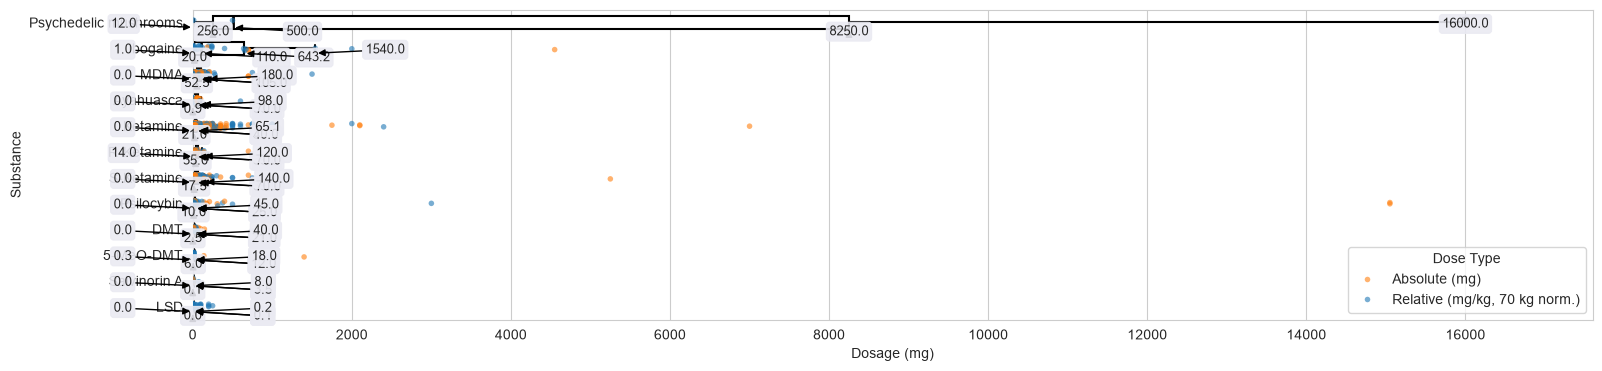

In [52]:
make_fig()